<h1><center>
    
## **DEEP LEARNING FOR DATA SCIENCE**

### Department of Mathematics and Applied Mathematics
[<img src="UJLogo.jpg" width="250"/>](UJLogo.jpg)
</center></h1>

# Examination

You have two Questions which you need to answer for this examination. Please answer each question posed under the relevant sections.


### Mark /100:

In [ ]:
#Mark =

### Average:

In [ ]:
#Mark/100*100

## QUESTION 1 [85 MARKS]

In this question you will consider a dataset that provides a comprehensive overview of various factors affecting student performance in exams. It includes information on study habits, attendance, parental involvement, and other aspects influencing academic success.
____________________

### 1. Load Libraries
____________________

In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn.datasets as dt
from sklearn.model_selection import train_test_split


____________________

### 2. Load Data
____________________

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
data = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/StudentPerformanceFactors_Exam.csv')


Mounted at /content/drive


In [ ]:
print(data.shape)
data.head()

(6607, 14)


,Hours_Studied,Attendance,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,School_Type,Physical_Activity,Parental_Education_Level,Gender,Exam_Score
0,23.0,84.0,High,7,73,Low,Yes,0,Low,Public,3,High School,Male,67.0
1,19.0,64.0,Medium,8,59,Low,Yes,2,Medium,Public,4,College,Female,61.0
2,24.0,98.0,Medium,7,91,Medium,Yes,2,Medium,Public,4,Postgraduate,Male,74.0
3,29.0,89.0,Medium,8,98,Medium,Yes,1,Medium,Public,4,High School,Male,71.0
4,19.0,92.0,Medium,6,65,Medium,Yes,3,Medium,Public,4,College,Female,70.0


____________________

### 3. Cleaning Data [27 Marks]
____________________

3.1 Usually when setting up a Machine Learning Workflow, you would need to split your data-set into a training set and a test set before implementing data pre-processing and cleaning. Why is this? **[1 Mark]**


In [ ]:
#Is to ensures that we evaluate the model's performance on data it has not seen during training providing a more accurate.
#This also helps to avoid overfitting the data .

3.2 Should your training set be small and lack diversity, what are your options in order to improve it for the purposes of training a Machine Learning algorithm on the data-set? **[1 Mark]**

In [ ]:
#I will make the model learn more from the see data
#I can try to increase the size of the data set

3.3 Given question 3.1, do the following:

3.3.1 Create the target variable ($y$) and feature data-set ($X$). **[2 Mark]**

3.3.2 Split the data-set (i.e. $X$ (features) and $y$ (target)) into training and testing data-sets, with a test data-set size of $35\%$. **[3 Mark]**




In [ ]:
#3.3.1 separate features and target variables
y = data['Exam_Score']
data.drop('Exam_Score', axis=1, inplace=True)
X=data

In [ ]:
#3.3.2 split the data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=42)

**We will now continue with data pre-processing and cleaning. Be careful to do so on the correct data-set.**


3.4 How many null values are present in each feature of the dataset? Explain your result. **[5 Marks]**


In [ ]:
#Check if the data is only features variable
data.head()

,Hours_Studied,Attendance,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,School_Type,Physical_Activity,Parental_Education_Level,Gender
0,23.0,84.0,High,7,73,Low,Yes,0,Low,Public,3,High School,Male
1,19.0,64.0,Medium,8,59,Low,Yes,2,Medium,Public,4,College,Female
2,24.0,98.0,Medium,7,91,Medium,Yes,2,Medium,Public,4,Postgraduate,Male
3,29.0,89.0,Medium,8,98,Medium,Yes,1,Medium,Public,4,High School,Male
4,19.0,92.0,Medium,6,65,Medium,Yes,3,Medium,Public,4,College,Female


In [ ]:
data.isnull().sum()

,0
Hours_Studied,20
Attendance,10
Access_to_Resources,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0
Family_Income,0
School_Type,0


In [ ]:
#Hours_Studied	has 20 null values
#Attendance has 10 null values
#Parental_Education_Level has 90 null values
#Gender has 7 null values

3.5 Remove the null values for each feature you identified in 3.4 and explain your reasoning. **[15 Marks]**


Text(0, 0.5, 'count')

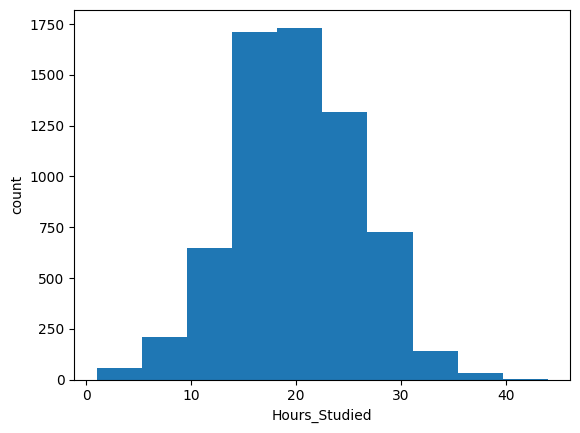

In [ ]:
#Check if Hours_Studied is a normal distriution
%matplotlib inline
import matplotlib.pyplot as plt
plt.hist(data["Hours_Studied"])

# set x/y labels and plot title
plt.xlabel("Hours_Studied")
plt.ylabel("count")

In [ ]:
#From the above visualisation we see that our distribution for Hours_Studied is normal, and is continous variable hence we replace null values by mean
avg_Hours_Studied= data['Hours_Studied'].mean(axis=0)
print("Average Hours_Studied:", avg_Hours_Studied)
data["Hours_Studied"]= data["Hours_Studied"].replace(np.nan,avg_Hours_Studied)

Average Hours_Studied: 19.971155305905572


Text(0, 0.5, 'count')

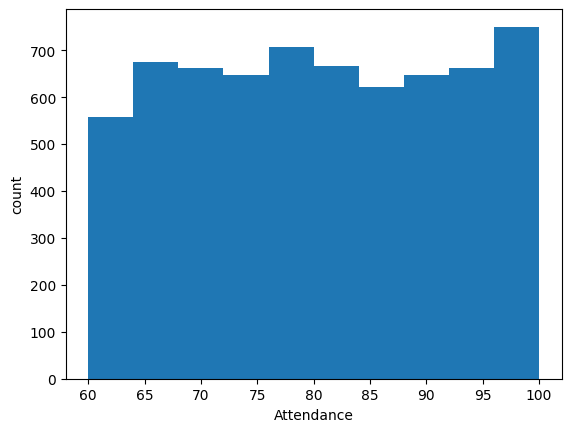

In [ ]:
#Check if Attendance is a normal distriution
%matplotlib inline
import matplotlib.pyplot as plt
plt.hist(data["Attendance"])

# set x/y labels and plot title
plt.xlabel("Attendance")
plt.ylabel("count")

In [ ]:
#From the above visualisation we see that our distribution for Attendance is not normal hence we replace null values by median
median=data["Attendance"].median()
print("Median of Attendance:", median)
data["Attendance"]= data["Attendance"].replace(np.nan, median)

Median of Attendance: 80.0


In [ ]:
#Parental_Education_Level
data["Parental_Education_Level"].value_counts()

,count
Parental_Education_Level,
High School,3223
College,1989
Postgraduate,1305


In [ ]:
mode = data["Parental_Education_Level"].mode()[0]
print("Modal of Parental_Education_Level:", mode)
data["Parental_Education_Level"]= data["Parental_Education_Level"].replace(np.nan,mode)

Modal of Parental_Education_Level: High School


In [ ]:
#For Gender
data["Gender"].value_counts()

,count
Gender,
Male,3811
Female,2789


In [ ]:
#Chech if we have percentage increase
3811/(3811+2789+7)*100

57.6812471621008

In [ ]:
(3811+7)/(3811+2789+7)*100

57.787195398819435

In [ ]:
#Since we have discrete variable and the percentage is increasin if we replace missing values by Male. We use frequency to replace null values of gender
data["Gender"]= data["Gender"].replace(np.nan,"Male")

In [ ]:
#Now chech if there are no null values on the feature set
data.isnull().sum()

,0
Hours_Studied,0
Attendance,0
Access_to_Resources,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0
Family_Income,0
School_Type,0


____________________

### 4. Data Processing [21 Marks]
____________________
4.1 Which features are objects? **[2 Marks]**


In [ ]:
data.dtypes

,0
Hours_Studied,float64
Attendance,float64
Access_to_Resources,object
Sleep_Hours,int64
Previous_Scores,int64
Motivation_Level,object
Internet_Access,object
Tutoring_Sessions,int64
Family_Income,object
School_Type,object


In [ ]:
#4.1
#Access_to_Resources
#Motivation_Level
#Internet_Access
#Family_Income
#School_Type
#Parental_Education_Level
#Gender

4.2 Convert the categorical data of the following list of features to ordinal data. Choose the following transforms: **[11 Marks]**

1. Internet_Access: Yes $\rightarrow$ 1; No $\rightarrow$ 0
2. Gender: Male $\rightarrow$ 1; Female $\rightarrow$ 0
3. Access_to_Resources: High $\rightarrow$ 2; Medium $\rightarrow$ 1; Low $\rightarrow$ 0
4. Motivation_Level: High $\rightarrow$ 2; Medium $\rightarrow$ 1; Low $\rightarrow$ 0
5. Family_Income: High $\rightarrow$ 2; Medium $\rightarrow$ 1; Low $\rightarrow$ 0

In [ ]:
#I will use the map() function to convert categorical to ordinal

In [ ]:
#4.2 (1)
mapping_Internet_Access={"Yes":1,"No":0}
data["Internet_Access"]=data["Internet_Access"].map(mapping_Internet_Access)

In [ ]:
#4.2(2)
mapping_Gender={"Male":1,"Female":0}
data["Gender"]=data["Gender"].map(mapping_Gender)

In [ ]:
#4.2(3)
mapping_Access_to_Resources={"High":2,"Medium":1,"Low":0}
data["Access_to_Resources"]=data["Access_to_Resources"].map(mapping_Access_to_Resources)

In [ ]:
#4.2(4)
mapping_Motivation_Level={"High":2,"Medium":1,"Low":0}
data["Motivation_Level"]=data["Motivation_Level"].map(mapping_Motivation_Level)

In [ ]:
#4.2(5)
mapping_Family_Income={"High":2,"Medium":1,"Low":0}
data["Family_Income"]=data["Family_Income"].map(mapping_Family_Income)

In [ ]:
data.head()

,Hours_Studied,Attendance,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,School_Type,Physical_Activity,Parental_Education_Level,Gender
0,23.0,84.0,2,7,73,0,1,0,0,Public,3,High School,1
1,19.0,64.0,1,8,59,0,1,2,1,Public,4,College,0
2,24.0,98.0,1,7,91,1,1,2,1,Public,4,Postgraduate,1
3,29.0,89.0,1,8,98,1,1,1,1,Public,4,High School,1
4,19.0,92.0,1,6,65,1,1,3,1,Public,4,College,0


4.3 Create dummy variables for the feature ```Parental_Education_Level``` and ```School_Type``` and replace the current feature with these dummy variables in your data-set. **[8 Marks]**


In [ ]:
#Dummy for Parental_Education_Level
dummy_variable_1 = pd.get_dummies(data["Parental_Education_Level"]).astype("int")
dummy_variable_1.head()

,College,High School,Postgraduate
0,0,1,0
1,1,0,0
2,0,0,1
3,0,1,0
4,1,0,0


In [ ]:
dummy_variable_1.rename(columns={'Parental_Education_Level':'College	', 'Parental_Education_Level':'High School','Parental_Education_Level':'Postgraduate'}, inplace=True)
# merge  "data" and "dummy_variable_1"
data = pd.concat([data, dummy_variable_1], axis=1)

# drop original column "Parental_Education_Level" from "data"
data.drop("Parental_Education_Level", axis = 1, inplace=True)

data.head()

,Hours_Studied,Attendance,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,School_Type,Physical_Activity,Gender,College,High School,Postgraduate
0,23.0,84.0,2,7,73,0,1,0,0,Public,3,1,0,1,0
1,19.0,64.0,1,8,59,0,1,2,1,Public,4,0,1,0,0
2,24.0,98.0,1,7,91,1,1,2,1,Public,4,1,0,0,1
3,29.0,89.0,1,8,98,1,1,1,1,Public,4,1,0,1,0
4,19.0,92.0,1,6,65,1,1,3,1,Public,4,0,1,0,0


In [ ]:
#Dummy for School_Type
dummy_variable_2 = pd.get_dummies(data["School_Type"]).astype("int")
dummy_variable_2.head()

,Private,Public
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


In [ ]:
dummy_variable_2.rename(columns={'School_Type':'Private	', 'School_Type':'Public'}, inplace=True)
# merge  "data" and "dummy_variable_1"
data = pd.concat([data, dummy_variable_2], axis=1)

# drop original column "Parental_Education_Level" from "data"
data.drop("School_Type", axis = 1, inplace=True)

data.head()

,Hours_Studied,Attendance,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Physical_Activity,Gender,College,High School,Postgraduate,Private,Public
0,23.0,84.0,2,7,73,0,1,0,0,3,1,0,1,0,0,1
1,19.0,64.0,1,8,59,0,1,2,1,4,0,1,0,0,0,1
2,24.0,98.0,1,7,91,1,1,2,1,4,1,0,0,1,0,1
3,29.0,89.0,1,8,98,1,1,1,1,4,1,0,1,0,0,1
4,19.0,92.0,1,6,65,1,1,3,1,4,0,1,0,0,0,1


____________________

### 5. Prediction [37 Marks]
____________________

5.1 Given the pre-processing structure you have implemented above, wrangle your test data-set appropriately. **[15 Marks]**



In [ ]:
#Get the test data
test_data=pd.concat([X_test,y_test],axis=1)
test_data.head()

,Hours_Studied,Attendance,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,School_Type,Physical_Activity,Parental_Education_Level,Gender,Exam_Score
743,20.0,71.0,Low,7,87,High,Yes,1,Medium,Public,5,High School,Male,65.0
5551,22.0,71.0,Low,7,98,Low,Yes,2,Low,Public,2,High School,Female,65.0
3442,21.0,91.0,Medium,6,53,High,Yes,1,Medium,Public,3,Postgraduate,Female,71.0
6571,12.0,91.0,Low,8,81,Low,Yes,0,Low,Public,4,High School,Male,64.0
4204,21.0,63.0,High,8,95,Medium,Yes,2,High,Public,5,High School,Male,66.0


In [ ]:
test_data.isnull().sum()

,0
Hours_Studied,6
Attendance,6
Access_to_Resources,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0
Family_Income,0
School_Type,0


In [ ]:
# rop whole row with NaN in "Exam_Score" column
before_rows = test_data.shape[0]
test_data.dropna(subset=["Exam_Score"], axis=0, inplace=True)
after_rows =test_data.shape[0]
print("Number of dropped rows {}".format(before_rows - after_rows))
#reset index, because we droped two rows
test_data.reset_index(drop=True, inplace=True)

Number of dropped rows 2


In [ ]:
#From the above visualisation we see that our distribution for Hours_Studied is normal hence we replace null values by mean
avg_Hours_Studied_test= test_data['Hours_Studied'].mean(axis=0)
print("Average Hours_Studied:", avg_Hours_Studied_test)
test_data["Hours_Studied"]= test_data["Hours_Studied"].replace(np.nan,avg_Hours_Studied_test)

Average Hours_Studied: 20.000867678958784


In [ ]:
#From the above visualisation we see that our distribution for Attendance is not normal hence we replace null values by median
median_test=test_data["Attendance"].median()
print("Median of Attendance:", median_test)
test_data["Attendance"]= test_data["Attendance"].replace(np.nan, median_test)

Median of Attendance: 79.0


In [ ]:
#Parental_Education_Level
test_data["Parental_Education_Level"].value_counts()

,count
Parental_Education_Level,
High School,1122
College,687
Postgraduate,471


In [ ]:
mode_test = test_data["Parental_Education_Level"].mode()[0]
print("Modal of Parental_Education_Level:", mode_test)
test_data["Parental_Education_Level"]= test_data["Parental_Education_Level"].replace(np.nan,mode_test)

Modal of Parental_Education_Level: High School


In [ ]:
#For Gender
test_data["Gender"].value_counts()

,count
Gender,
Male,1304
Female,1005


In [ ]:
#Since we have discrete variable and the percentage is increasin if we replace missing values by Male. We use frequenct to replace null values of gender
test_data["Gender"]= test_data["Gender"].replace(np.nan,"Male")

In [ ]:
#Data  processing
#I will use the map() function to convert categorical to ordinal

In [ ]:
mapping_Internet_Access={"Yes":1,"No":0}
test_data["Internet_Access"]=test_data["Internet_Access"].map(mapping_Internet_Access)

mapping_Gender={"Male":1,"Female":0}
test_data["Gender"]=test_data["Gender"].map(mapping_Gender)

mapping_Access_to_Resources={"High":2,"Medium":1,"Low":0}
test_data["Access_to_Resources"]=test_data["Access_to_Resources"].map(mapping_Access_to_Resources)

mapping_Motivation_Level={"High":2,"Medium":1,"Low":0}
test_data["Motivation_Level"]=test_data["Motivation_Level"].map(mapping_Motivation_Level)

mapping_Family_Income={"High":2,"Medium":1,"Low":0}
test_data["Family_Income"]=test_data["Family_Income"].map(mapping_Family_Income)

In [ ]:
dummy_variable_3 = pd.get_dummies(test_data["Parental_Education_Level"]).astype("int")
dummy_variable_3.head()

,College,High School,Postgraduate
0,0,1,0
1,0,1,0
2,0,0,1
3,0,1,0
4,0,1,0


In [ ]:
dummy_variable_3.rename(columns={'Parental_Education_Level':'College	', 'Parental_Education_Level':'High School','Parental_Education_Level':'Postgraduate'}, inplace=True)
# merge  "data" and "dummy_variable_1"
test_data = pd.concat([test_data, dummy_variable_3], axis=1)

# drop original column "Parental_Education_Level" from "data"
test_data.drop("Parental_Education_Level", axis = 1, inplace=True)

test_data.head()

,Hours_Studied,Attendance,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,School_Type,Physical_Activity,Gender,Exam_Score,College,High School,Postgraduate
0,20.0,71.0,0,7,87,2,1,1,1,Public,5,1,65.0,0,1,0
1,22.0,71.0,0,7,98,0,1,2,0,Public,2,0,65.0,0,1,0
2,21.0,91.0,1,6,53,2,1,1,1,Public,3,0,71.0,0,0,1
3,12.0,91.0,0,8,81,0,1,0,0,Public,4,1,64.0,0,1,0
4,21.0,63.0,2,8,95,1,1,2,2,Public,5,1,66.0,0,1,0


In [ ]:
#Dummy for School_Type
dummy_variable_4 = pd.get_dummies(test_data["School_Type"]).astype("int")
dummy_variable_4.head()

,Private,Public
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


In [ ]:
dummy_variable_4.rename(columns={'School_Type':'Private	', 'School_Type':'Public'}, inplace=True)
# merge  "data" and "dummy_variable_1"
test_data = pd.concat([test_data, dummy_variable_4], axis=1)

# drop original column "Parental_Education_Level" from "data"
test_data.drop("School_Type", axis = 1, inplace=True)

test_data.head()

,Hours_Studied,Attendance,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Physical_Activity,Gender,Exam_Score,College,High School,Postgraduate,Private,Public
0,20.0,71.0,0,7,87,2,1,1,1,5,1,65.0,0,1,0,0,1
1,22.0,71.0,0,7,98,0,1,2,0,2,0,65.0,0,1,0,0,1
2,21.0,91.0,1,6,53,2,1,1,1,3,0,71.0,0,0,1,0,1
3,12.0,91.0,0,8,81,0,1,0,0,4,1,64.0,0,1,0,0,1
4,21.0,63.0,2,8,95,1,1,2,2,5,1,66.0,0,1,0,0,1


 5.2 Use the following two models: **[8 Marks]**
- ```Ridge```
- ```Lasso```

to obtain predictions which you can compare to the test data-set obtained above, and provide the following accuracy scores for each model: **[12 Marks]**

- ```r2_score```
- ```mean_squared_error```
- ```explained_variance_score```
    
Be sure to assess your model scores on the test data-set: (```X_test```,```y_test```). You need to obtain an ```r2_score``` of at least an $60$% for each model.



In [ ]:
data_new=pd.concat([data,y],axis=1)
data_new.head()

,Hours_Studied,Attendance,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Physical_Activity,Gender,College,High School,Postgraduate,Private,Public,Exam_Score
0,23.0,84.0,2,7,73,0,1,0,0,3,1,0,1,0,0,1,67.0
1,19.0,64.0,1,8,59,0,1,2,1,4,0,1,0,0,0,1,61.0
2,24.0,98.0,1,7,91,1,1,2,1,4,1,0,0,1,0,1,74.0
3,29.0,89.0,1,8,98,1,1,1,1,4,1,0,1,0,0,1,71.0
4,19.0,92.0,1,6,65,1,1,3,1,4,0,1,0,0,0,1,70.0


In [ ]:
# drop whole row with NaN in "Exam_Score" column
before_rows = data_new.shape[0]
data_new.dropna(subset=["Exam_Score"], axis=0, inplace=True)
after_rows =data_new.shape[0]
print("Number of dropped rows {}".format(before_rows - after_rows))
#reset index, because we droped two rows
data.reset_index(drop=True, inplace=True)

Number of dropped rows 7


In [ ]:
y_new=data_new["Exam_Score"]
X_new=data_new.drop("Exam_Score",axis=1)

In [ ]:
#Split the new data set
X_train,X_test,y_train,y_test= train_test_split(X_new,y_new,test_size=0.35,random_state=0)

In [ ]:
#y_test=test_data["Exam_Score"]
#X_test=test_data.drop("Exam_Score",axis=1)

In [ ]:
#5.2Ridge
from sklearn.linear_model import Ridge

ridge=Ridge().fit(X_train, y_train)
ridge.fit(X_train, y_train)
Y_pred_R=ridge.predict(X_test)
acc_R=ridge.score(X_test, y_test) * 100
print("score for Ridge mode:",acc_R)

score for Ridge mode: 66.06316345994605


In [ ]:
#5.2 lasso
from sklearn.linear_model import Lasso

lass=Lasso().fit(X_train, y_train)
lass.fit(X_train, y_train)
Y_pred_Las=lass.predict(X_test)
acc_lass=lass.score(X_test, y_test) * 100
print("Score for Lasso mode:", acc_lass)

Score for Lasso mode: 57.64347999401478


In [ ]:
#5.2Ridge
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, explained_variance_score

ridge=Ridge().fit(X_train, y_train)
ridge.fit(X_train, y_train)
Y_pred_R=ridge.predict(X_test)
acc_R=ridge.score(X_test, y_test) * 100
print("score for Ridge mode:",acc_R)

mse_R = mean_squared_error(y_test, Y_pred_R)
print("Mean Squared Error:{:.3f} ".format(mse_R))

evs_R = explained_variance_score(y_test, Y_pred_R)
print("Explained Variance Score:{:.3f} ".format(evs_R))

score for Ridge mode: 66.06316345994605
Mean Squared Error:4.979 
Explained Variance Score:0.661 


In [ ]:
#5.2 lasso
from sklearn.linear_model import Lasso

lass=Lasso().fit(X_train, y_train)
lass.fit(X_train, y_train)
Y_pred_Las=lass.predict(X_test)
acc_lass=lass.score(X_test, y_test) * 100
print("Score for Lasso mode:", acc_lass)

mse_L= mean_squared_error(y_test, Y_pred_Las)
print("Mean Squared Error:{:.3f} ".format(mse_L))

evs_L = explained_variance_score(y_test, Y_pred_Las)
print("Explained Variance Score:{:.3f} ".format(evs_L))

Score for Lasso mode: 57.64347999401478
Mean Squared Error:6.214 
Explained Variance Score:0.576 


In [ ]:
#On this data set Ridge model perform much better than Lasso model since Ridge model has high score and less mean square error

5.3 Do the models (```Ridge``` and ```Lasso```) utilised, perform better when $\alpha >1$ or $\alpha <1$? Provide an answer for each model. **[2 Marks]**

In [ ]:
#Yes, since hyperparameter turning increases the accuracy of the model


## QUESTION 2 [15 Marks]


In this question you are considering the optical recognition of handwritten digits. The data-set contains images of hand-written digits with 10 classes where each class refers to a digit.

____________________

### 1. Load Libraries
____________________



In [ ]:
# Load the digits dataset with two classes
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn.datasets as dt
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_digits

____________________

### 2. Load Data
____________________

The optical recognition of handwritten digits data-set is loaded using ```load_digits()```.

In [ ]:
# Load the dataset
digits = load_digits()

____________________

### 3. Classification **[15 Marks]**
____________________


You need to use the following model to classify the digit given the data:
 - ```MLPClassifier```

You need to:
1. Split the data-set into a test and train set. **[1 Mark]**
2. Set up your ```MLPClassifier``` with appropriate hyperparameters and solver. **[4 Marks]**
3. Perform an accuracy assessment on the classification of *each digit* by using the following assessment scoring methods:
    - ```accuracy_score```
    - ```precision_score```
    - ```recall_score```
    - ```f1-score```

One way to assess the above scores of the model is by using the ```classification_report``` module, however you may also use the individual modules: ```accuracy_score, precision_score, recall_score, f1_score```. You must be sure to do so on the test data-set: (```X_test```,```y_test```). You need to obtain an ```accuracy score``` of least an $80$% for the model. **[10 Marks]**



In [ ]:
#3(1)
#y=digits.target
#X=digits.data

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target,  random_state=42)


In [ ]:
#3(2)
from sklearn.neural_network import MLPClassifier
#Lets choose our hyperparameters , as solver to be "lbfgs" and our activation fuction as tanh
mlp = MLPClassifier(solver="lbfgs", activation="tanh")
mlp.fit(X_train, y_train)
score=mlp.score(X_test, y_test)
acc_MLP= mlp.score(X_test, y_test) * 100
print(f'MPL Classifier Accuracy: {acc_MLP:.2f}')

MPL Classifier Accuracy: 96.89


In [ ]:
#3(3)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import  precision_score
from sklearn.metrics import  recall_score
from sklearn.metrics import  f1_score
from sklearn.metrics import classification_report

#Lets choose our hyperparameters , as solver to be "lbfgs" and our activation fuction as tanh
mlp = MLPClassifier(solver="lbfgs", activation="tanh")
mlp.fit(X_train, y_train)
Y_pred = mlp.predict(X_test)

#Accuracy score
acc_score=accuracy_score(y_test,Y_pred)
print(f'Accuracy score: {acc_score:.2f}')

#Precision score
pre_score=precision_score(y_test,Y_pred, average="weighted")
print(f'Precision score: {pre_score:.2f}')

#Recall score
rec_score=recall_score(y_test,Y_pred, average="weighted")
print(f'Recall score: {rec_score:.2f}')

#f1 score
f1_score=f1_score(y_test,Y_pred, average="weighted")
print(f'f1 score: {f1_score:.2f}')


#classification report
print("Classification Report:")
print(classification_report(y_test, Y_pred))

Accuracy score: 0.98
Precision score: 0.98
Recall score: 0.98
f1 score: 0.98
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        43
           1       1.00      1.00      1.00        37
           2       0.95      1.00      0.97        38
           3       1.00      0.93      0.97        46
           4       1.00      1.00      1.00        55
           5       0.97      0.97      0.97        59
           6       0.98      0.98      0.98        45
           7       1.00      0.95      0.97        41
           8       0.93      0.97      0.95        38
           9       0.96      0.98      0.97        48

    accuracy                           0.98       450
   macro avg       0.98      0.98      0.98       450
weighted avg       0.98      0.98      0.98       450

